# Dataset Statistics for Split Design

This notebook starts from the clustering representatives table and enriches each protein with:
- protein-level PDB/DisProt/CAID flags,
- cluster-level AF2/CAID flags,
- cluster fixed split label (`training` / `caid` / `missing`).

Then it resolves clusters with missing fixed labels using a DisProt release-date cutoff:
- for each cluster, compute the minimum (oldest) DisProt release date among members,
- label missing clusters as `testing` when this minimum date is more recent than the cutoff,
- otherwise label them as `training`.

The notebook also compares multiple cutoffs and reports IDR-binding annotated proteins/clusters by set label.

In [1]:
# Setup the scripts environment.
import Pkg
Pkg.activate(@__DIR__)
Pkg.instantiate()

  Activating project at `~/.julia/dev/IDRBindingDataset.jl/scripts`


In [2]:
using CodecZlib
using CSV
using DataFrames
using Dates
using Plots
using IDRBindingDataset:
    assign_missing_cluster_labels_by_disprot_cutoff,
    build_dataset_stats_table,
    build_disprot_protein_annotations,
    build_disprot_release_dates,
    build_oldest_pdb_release_dates,
    read_caid_disprot_ids,
    read_disprot_entries_from_raw_data,
    summarize_dataset_labels_by_binding,
    sweep_disprot_cutoff_label_summaries

In [3]:
plotly()

Plots.PlotlyBackend()

## Inputs

All inputs are read-only files already present under `data/raw` and `data/derived`.

In [4]:
const RAW_DATA_DIR = normpath(joinpath(@__DIR__, "..", "data", "raw"))
const DERIVED_DATA_DIR = normpath(joinpath(@__DIR__, "..", "data", "derived"))

const CLUSTER_REPRESENTATIVES_PATH = joinpath(
    DERIVED_DATA_DIR,
    "clustering",
    "cluster_representatives.csv.gz"
)
const PDB_RELEASE_MAP_PATH = joinpath(
    DERIVED_DATA_DIR,
    "pdb",
    "uniprot_pdb_release_date_map.csv.gz"
)
const CAID2_BINDING_FASTA_PATH = joinpath(RAW_DATA_DIR, "caid_2", "binding.fasta.gz")
const CAID3_BINDING_FASTA_PATH = joinpath(RAW_DATA_DIR, "caid_3", "binding.fasta.gz")
const CAID3_BINDING_IDR_FASTA_PATH = joinpath(RAW_DATA_DIR, "caid_3", "binding_idr.fasta.gz")

(
    cluster_representatives = CLUSTER_REPRESENTATIVES_PATH,
    pdb_release_map = PDB_RELEASE_MAP_PATH,
    caid2_binding = CAID2_BINDING_FASTA_PATH,
    caid3_binding = CAID3_BINDING_FASTA_PATH,
    caid3_binding_idr = CAID3_BINDING_IDR_FASTA_PATH
)

(cluster_representatives = "/home/diego.zea/.julia/dev/IDRBindingDataset.jl/data/derived/clustering/cluster_representatives.csv.gz", pdb_release_map = "/home/diego.zea/.julia/dev/IDRBindingDataset.jl/data/derived/pdb/uniprot_pdb_release_date_map.csv.gz", caid2_binding = "/home/diego.zea/.julia/dev/IDRBindingDataset.jl/data/raw/caid_2/binding.fasta.gz", caid3_binding = "/home/diego.zea/.julia/dev/IDRBindingDataset.jl/data/raw/caid_3/binding.fasta.gz", caid3_binding_idr = "/home/diego.zea/.julia/dev/IDRBindingDataset.jl/data/raw/caid_3/binding_idr.fasta.gz")

In [5]:
cluster_representatives = open(GzipDecompressorStream, CLUSTER_REPRESENTATIVES_PATH) do io
    CSV.read(io, DataFrame)
end

first(cluster_representatives, 10)

Row,protein_id,global_representative_id,local_representative_id,final_cluster_id
,String15,String15,String15,String15
1,A0A024B7W1,A0A024B7W1,A0A024B7W1,cluster_000001
2,A0A068MVV3,A0A068MVV3,A0A068MVV3,cluster_000002
3,A0A078IB52,A0A078IB52,A0A078IB52,cluster_000003
4,A0A090N8E9,A0A090N8E9,A0A090N8E9,cluster_000004
5,A0A097F4I8,A0A097F4I8,A0A097F4I8,cluster_000005
6,A0A0B4JDC9,A0A0B4JDC9,A0A0B4JDC9,cluster_000006
7,A0A0C4DGY3,A0A0C4DGY3,A0A0C4DGY3,cluster_000007
8,A0A0G2JXC5,A0A0G2JXC5,A0A0G2JXC5,cluster_000008
9,A0A0G2KTI4,A0A0G2KTI4,A0A0G2KTI4,cluster_000009


In [6]:
pdb_release_map = open(GzipDecompressorStream, PDB_RELEASE_MAP_PATH) do io
    CSV.read(io, DataFrame)
end
oldest_pdb_release_dates = build_oldest_pdb_release_dates(pdb_release_map)

first(oldest_pdb_release_dates, 10)

Row,acc,oldest_pdb_release_date,has_pdb_structure,has_missing_pdb_release_date
,String,Date,Bool,Bool
1,A0A024B7W1,2016-03-30,true,false
2,A0A090N8E9,2013-09-25,true,false
3,A0A097F4I8,2021-05-05,true,false
4,A0A0B4JDC9,2015-08-05,true,false
5,A0A0C4DGY3,2020-01-29,true,false
6,A0A0G2KTI4,2019-07-31,true,false
7,A0A0H2UWN8,2018-11-14,true,false
8,A0A0H2XCS3,2016-05-04,true,false
9,A0A0H2ZP82,2013-11-20,true,false


In [7]:
disprot_entries = read_disprot_entries_from_raw_data(RAW_DATA_DIR)
first(disprot_entries, 3)

3-element Vector{Any}:
 JSON.Object{String, Any}("acc" => "P03265", "sequence" => "MASREEEQRETTPERGRGAARRPPTMEDVSSPSPSPPPPRAPPKKRMRRRIESEDEEDSSQDALVPRTPSPRPSTSAADLAIAPKKKKKRPSPKPERPPSPEVIVDSEEEREDVALQMVGFSNPPVLIKHGKGGKRTVRRLNEDDPVARGMRTQEEEEEPSEAESEITVMNPLSVPIVSAWEKGMEAARALMDKYHVDNDLKANFKLLPDQVEALAAVCKTWLNEEHRGLQLTFTSKKTFVTMMGRFLQAYLQSFAEVTYKHHEPTGCALWLHRCAEIEGELKCLHGSIMINKEHVIEMDVTSENGQRALKEQSSKAKIVKNRWGRNVVQISNTDARCCVHDAACPANQFSGKSCGMFFSEGAKAQVAFKQIKAFMQALYPNAQTGHGHLLMPLRCECNSKPGHAPFLGRQLPKLTPFALSNAEDLDADLISDKSVLASVHHPALIVFQCCNPVYRNSRAQGGGPNCDFKISAPDLLNALVMVRSLWSENFTELPRMVVPEFKWSTKHQYRNVSLPVAHSDARQNPFDF", "creator" => "gminervini", "dataset" => Any["Viral proteins"], "date" => "2016-08-22T14:31:42.000Z", "disprot_id" => "DP00003", "features" => JSON.Object{String, Any}("pfam" => Any[JSON.Object{String, Any}("id" => "PF02236", "name" => "Viral DNA-binding protein, all alpha domain", "start" => 184, "end" => 262), JSON.Object{String, Any}("id" => "PF03728", "name" => "Viral DNA-binding

In [8]:
disprot_annotations = build_disprot_protein_annotations(disprot_entries)
first(disprot_annotations, 10)

Row,acc,disprot_id,oldest_disprot_release_date,has_idr_binding_annotation
,String,String,Date?,Bool
1,A0A024B7W1,DP03773,2022-12-01,true
2,A0A068MVV3,DP01148,2018-11-01,true
3,A0A078IB52,DP04200,2024-06-01,true
4,A0A090N8E9,DP03755,2022-12-01,false
5,A0A097F4I8,DP03539,2021-12-01,false
6,A0A0B4JDC9,DP04096,2023-12-01,false
7,A0A0C4DGY3,DP04114,2023-06-01,false
8,A0A0G2JXC5,DP01139,2018-11-01,true
9,A0A0G2KTI4,DP03824,2023-12-01,false


In [9]:
caid2_disprot_ids = read_caid_disprot_ids(CAID2_BINDING_FASTA_PATH)
caid3_disprot_ids = read_caid_disprot_ids(CAID3_BINDING_FASTA_PATH)

DataFrame(
    dataset = ["caid_2_binding", "caid_3_binding"],
    n_disprot_ids = [length(caid2_disprot_ids), length(caid3_disprot_ids)]
)

Row,dataset,n_disprot_ids
,String,Int64
1,caid_2_binding,78
2,caid_3_binding,52


In [10]:
# Are the proteins in CAID3 `binding` dataset also in the `binding_idr` one?

caid3_binding_idr_disprot_ids = read_caid_disprot_ids(CAID3_BINDING_IDR_FASTA_PATH)

caid3_binding_in_binding_idr = isempty(setdiff(caid3_disprot_ids, caid3_binding_idr_disprot_ids))

overlap_summary = DataFrame(
    metric = [
        "caid3_binding_ids",
        "caid3_binding_idr_ids",
        "caid3_binding_intersection_binding_idr",
        "caid3_binding_only_ids",
        "caid3_binding_is_subset_of_binding_idr"
    ],
    value = Int[
        length(caid3_disprot_ids),
        length(caid3_binding_idr_disprot_ids),
        length(intersect(caid3_disprot_ids, caid3_binding_idr_disprot_ids)),
        length(setdiff(caid3_disprot_ids, caid3_binding_idr_disprot_ids)),
        caid3_binding_in_binding_idr
    ]
)

overlap_summary

Row,metric,value
,String,Int64
1,caid3_binding_ids,52
2,caid3_binding_idr_ids,52
3,caid3_binding_intersection_binding_idr,52
4,caid3_binding_only_ids,0
5,caid3_binding_is_subset_of_binding_idr,1


## Build Protein-Level Dataset Statistics

In [11]:
dataset_stats = build_dataset_stats_table(
    cluster_representatives,
    disprot_annotations,
    oldest_pdb_release_dates,
    caid2_disprot_ids,
    caid3_disprot_ids
)

first(dataset_stats, 10)

Row,protein_id,global_representative_id,local_representative_id,final_cluster_id,protein_disprot_id,protein_oldest_disprot_release_date,protein_has_idr_binding_annotation,protein_oldest_pdb_release_date,protein_has_pdb_structure,protein_has_missing_pdb_release_date,protein_in_caid2,protein_in_caid3,protein_in_af2_training_set,cluster_in_af2_training_set,cluster_in_caid2,cluster_in_caid3,cluster_fixed_dataset_label
,String15,String15,String15,String15,String?,Date?,Bool,Date?,Bool,Bool,Bool,Bool,Bool,Bool?,Bool?,Bool?,String?
1,A0A024B7W1,A0A024B7W1,A0A024B7W1,cluster_000001,DP03773,2022-12-01,true,2016-03-30,true,false,false,false,true,true,false,false,training
2,A0A068MVV3,A0A068MVV3,A0A068MVV3,cluster_000002,DP01148,2018-11-01,true,missing,false,false,false,false,false,false,false,false,missing
3,A0A078IB52,A0A078IB52,A0A078IB52,cluster_000003,DP04200,2024-06-01,true,missing,false,false,false,false,false,false,false,true,caid
4,A0A090N8E9,A0A090N8E9,A0A090N8E9,cluster_000004,DP03755,2022-12-01,false,2013-09-25,true,false,false,false,true,true,false,false,training
5,A0A097F4I8,A0A097F4I8,A0A097F4I8,cluster_000005,DP03539,2021-12-01,false,2021-05-05,true,false,false,false,false,true,false,false,training
6,A0A0B4JDC9,A0A0B4JDC9,A0A0B4JDC9,cluster_000006,DP04096,2023-12-01,false,2015-08-05,true,false,false,false,true,true,true,false,caid
7,A0A0C4DGY3,A0A0C4DGY3,A0A0C4DGY3,cluster_000007,DP04114,2023-06-01,false,2020-01-29,true,false,false,false,false,false,false,false,missing
8,A0A0G2JXC5,A0A0G2JXC5,A0A0G2JXC5,cluster_000008,DP01139,2018-11-01,true,missing,false,false,false,false,false,true,false,false,training
9,A0A0G2KTI4,A0A0G2KTI4,A0A0G2KTI4,cluster_000009,DP03824,2023-12-01,false,2019-07-31,true,false,false,false,false,true,false,false,training


In [12]:
select(
    first(dataset_stats, 10),
    :protein_id,
    :final_cluster_id,
    :protein_oldest_disprot_release_date,
    :protein_oldest_pdb_release_date,
    :protein_has_pdb_structure,
    :protein_has_missing_pdb_release_date,
    :protein_in_caid2,
    :protein_in_caid3,
    :protein_in_af2_training_set,
    :cluster_in_af2_training_set,
    :cluster_in_caid2,
    :cluster_in_caid3,
    :cluster_fixed_dataset_label
)

Row,protein_id,final_cluster_id,protein_oldest_disprot_release_date,protein_oldest_pdb_release_date,protein_has_pdb_structure,protein_has_missing_pdb_release_date,protein_in_caid2,protein_in_caid3,protein_in_af2_training_set,cluster_in_af2_training_set,cluster_in_caid2,cluster_in_caid3,cluster_fixed_dataset_label
,String15,String15,Date?,Date?,Bool,Bool,Bool,Bool,Bool,Bool?,Bool?,Bool?,String?
1,A0A024B7W1,cluster_000001,2022-12-01,2016-03-30,true,false,false,false,true,true,false,false,training
2,A0A068MVV3,cluster_000002,2018-11-01,missing,false,false,false,false,false,false,false,false,missing
3,A0A078IB52,cluster_000003,2024-06-01,missing,false,false,false,false,false,false,false,true,caid
4,A0A090N8E9,cluster_000004,2022-12-01,2013-09-25,true,false,false,false,true,true,false,false,training
5,A0A097F4I8,cluster_000005,2021-12-01,2021-05-05,true,false,false,false,false,true,false,false,training
6,A0A0B4JDC9,cluster_000006,2023-12-01,2015-08-05,true,false,false,false,true,true,true,false,caid
7,A0A0C4DGY3,cluster_000007,2023-06-01,2020-01-29,true,false,false,false,false,false,false,false,missing
8,A0A0G2JXC5,cluster_000008,2018-11-01,missing,false,false,false,false,false,true,false,false,training
9,A0A0G2KTI4,cluster_000009,2023-12-01,2019-07-31,true,false,false,false,false,true,false,false,training


In [13]:
af2_in_caid_count = count(
    row -> row.protein_in_af2_training_set && row.cluster_fixed_dataset_label == "caid",
    eachrow(dataset_stats)
)

cluster_membership = unique(
    select(
        dataset_stats,
        :final_cluster_id,
        :cluster_in_af2_training_set,
        :cluster_in_caid2,
        :cluster_in_caid3
    )
)

DataFrame(
    metric = [
        "proteins",
        "final_clusters",
        "proteins_with_pdb",
        "proteins_with_missing_pdb_release_date",
        "proteins_in_caid2",
        "proteins_in_caid3",
        "proteins_with_binding_idr_annotation",
        "proteins_in_af2_training_set",
        "clusters_in_af2_training_set",
        "clusters_in_caid2",
        "clusters_in_caid3",
        "af2_training_proteins_in_caid"
    ],
    value = Any[
        nrow(dataset_stats),
        nrow(cluster_membership),
        count(dataset_stats.protein_has_pdb_structure),
        count(dataset_stats.protein_has_missing_pdb_release_date),
        count(dataset_stats.protein_in_caid2),
        count(dataset_stats.protein_in_caid3),
        count(dataset_stats.protein_has_idr_binding_annotation),
        count(dataset_stats.protein_in_af2_training_set),
        count(x -> !ismissing(x) && x, cluster_membership.cluster_in_af2_training_set),
        count(x -> !ismissing(x) && x, cluster_membership.cluster_in_caid2),
        count(x -> !ismissing(x) && x, cluster_membership.cluster_in_caid3),
        af2_in_caid_count
    ]
)

Row,metric,value
,String,Any
1,proteins,3199
2,final_clusters,2439
3,proteins_with_pdb,2781
4,proteins_with_missing_pdb_release_date,10
5,proteins_in_caid2,62
6,proteins_in_caid3,52
7,proteins_with_binding_idr_annotation,1075
8,proteins_in_af2_training_set,2512
9,clusters_in_af2_training_set,1995


## Requested Overlap

In [14]:
af2_in_caid_count

205

## Fixed Label Distribution

In [15]:
split_distribution = combine(
    groupby(dataset_stats, :cluster_fixed_dataset_label),
    nrow => :n_proteins,
    :final_cluster_id => (x -> length(unique(x))) => :n_final_clusters
)
sort!(split_distribution, :cluster_fixed_dataset_label)
split_distribution

Row,cluster_fixed_dataset_label,n_proteins,n_final_clusters
,String?,Int64,Int64
1,caid,311,103
2,training,2448,1936
3,missing,440,400


In [16]:
label_columns = [
    :protein_has_idr_binding_annotation,
    :protein_in_caid2,
    :protein_in_caid3,
    :protein_has_pdb_structure,
    :protein_has_missing_pdb_release_date,
    :protein_in_af2_training_set,
    :cluster_in_caid2,
    :cluster_in_caid3,
    :cluster_in_af2_training_set
]

label_long = stack(
    select(dataset_stats, :final_cluster_id, label_columns...),
    label_columns;
    variable_name = :label,
    value_name = :value
)

cluster_label_distribution = combine(
    groupby(label_long, [:label, :value]),
    :final_cluster_id => (x -> length(unique(x))) => :n_final_clusters,
    nrow => :n_proteins
)

# value indicates whether the label is true or false
sort!(cluster_label_distribution, [:label, :value])
cluster_label_distribution

Row,label,value,n_final_clusters,n_proteins
,String,Bool?,Int64,Int64
1,cluster_in_af2_training_set,false,444,489
2,cluster_in_af2_training_set,true,1995,2710
3,cluster_in_caid2,false,2386,2951
4,cluster_in_caid2,true,53,248
5,cluster_in_caid3,false,2388,3128
6,cluster_in_caid3,true,51,71
7,protein_has_idr_binding_annotation,false,1737,2124
8,protein_has_idr_binding_annotation,true,863,1075
9,protein_has_missing_pdb_release_date,false,2433,3189


### Plot 1: Proteins per Fixed Dataset Label

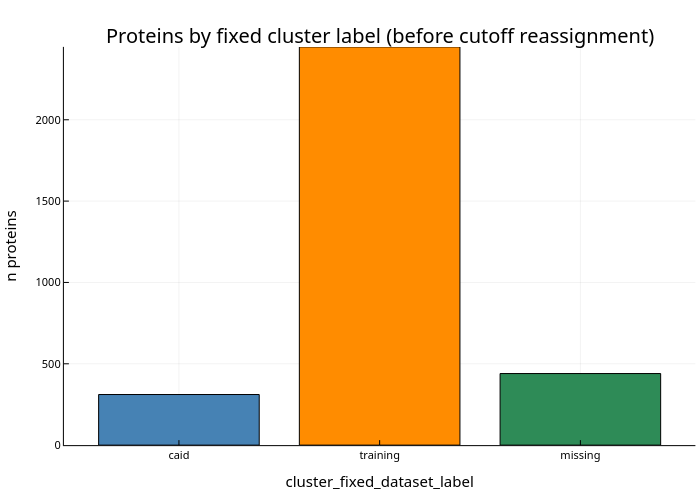

In [17]:
split_plot_rows = sort(split_distribution, :cluster_fixed_dataset_label)
split_labels = [ismissing(label) ? "missing" : String(label) for label in split_plot_rows.cluster_fixed_dataset_label]

bar(
    split_labels,
    split_plot_rows.n_proteins;
    xlabel = "cluster_fixed_dataset_label",
    ylabel = "n proteins",
    title = "Proteins by fixed cluster label (before cutoff reassignment)",
    legend = false,
    color = [:steelblue, :darkorange, :seagreen][1:length(split_labels)]
)

### Plot 2: Proteins per Boolean Label Value

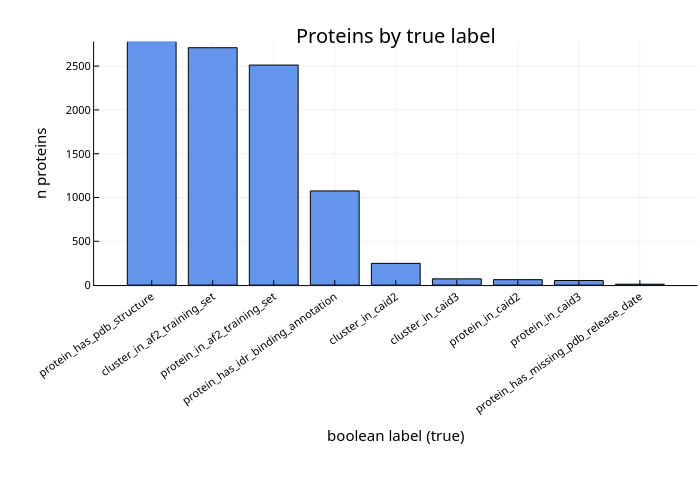

In [18]:
protein_true_rows = filter(:value => identity, cluster_label_distribution)
sort!(protein_true_rows, :n_proteins, rev = true)

bar(
    string.(protein_true_rows.label),
    protein_true_rows.n_proteins;
    xlabel = "boolean label (true)",
    ylabel = "n proteins",
    title = "Proteins by true label",
    legend = false,
    xrotation = 35,
    color = :cornflowerblue,
    size = (1000, 500)
)

## Cutoff Sweep Comparison

Compare all DisProt release versions as cutoff candidates and inspect how total and IDR-binding counts move across
`training`/`caid`/`testing`.

In [19]:
disprot_testing_cutoff_dates = build_disprot_release_dates(disprot_entries)

cutoff_span = DataFrame(
    metric = ["n_disprot_release_cutoffs", "first_cutoff", "last_cutoff"],
    value = [
        length(disprot_testing_cutoff_dates),
        first(disprot_testing_cutoff_dates),
        last(disprot_testing_cutoff_dates)
    ]
)

cutoff_sweep_summary = sweep_disprot_cutoff_label_summaries(
    dataset_stats;
    disprot_testing_cutoff_dates = disprot_testing_cutoff_dates
)

(
    cutoff_span = cutoff_span,
    first_rows = first(cutoff_sweep_summary, 18)
)

(cutoff_span = 3×2 DataFrame
 Row │ metric                     value      
     │ String                     Any        
─────┼───────────────────────────────────────
   1 │ n_disprot_release_cutoffs  16
   2 │ first_cutoff               2016-10-01
   3 │ last_cutoff                2025-12-01, first_rows = 18×6 DataFrame
 Row │ disprot_testing_cutoff_date  dataset_label  n_proteins  n_final_cluster ⋯
     │ Date                         String         Int64       Int64           ⋯
─────┼──────────────────────────────────────────────────────────────────────────
   1 │ 2016-10-01                   training             2547              202 ⋯
   2 │ 2016-10-01                   caid                  311               10
   3 │ 2016-10-01                   testing               341               31
   4 │ 2018-11-01                   training             2640              209
   5 │ 2018-11-01                   caid                  311               10 ⋯
   6 │ 2018-11-01                  

In [20]:
sweep_proteins_wide = unstack(
    select(cutoff_sweep_summary, :disprot_testing_cutoff_date, :dataset_label, :n_proteins),
    :disprot_testing_cutoff_date,
    :dataset_label,
    :n_proteins
)
sort!(sweep_proteins_wide, :disprot_testing_cutoff_date)

sweep_clusters_wide = unstack(
    select(cutoff_sweep_summary, :disprot_testing_cutoff_date, :dataset_label, :n_final_clusters),
    :disprot_testing_cutoff_date,
    :dataset_label,
    :n_final_clusters
)
sort!(sweep_clusters_wide, :disprot_testing_cutoff_date)

sweep_binding_proteins_wide = unstack(
    select(cutoff_sweep_summary, :disprot_testing_cutoff_date, :dataset_label, :n_idr_binding_proteins),
    :disprot_testing_cutoff_date,
    :dataset_label,
    :n_idr_binding_proteins
)
sort!(sweep_binding_proteins_wide, :disprot_testing_cutoff_date)

sweep_binding_clusters_wide = unstack(
    select(cutoff_sweep_summary, :disprot_testing_cutoff_date, :dataset_label, :n_idr_binding_clusters),
    :disprot_testing_cutoff_date,
    :dataset_label,
    :n_idr_binding_clusters
)
sort!(sweep_binding_clusters_wide, :disprot_testing_cutoff_date)

(
    proteins = sweep_proteins_wide,
    idr_binding_proteins = sweep_binding_proteins_wide
)

(proteins = 16×4 DataFrame
 Row │ disprot_testing_cutoff_date  training  caid    testing 
     │ Date                         Int64?    Int64?  Int64?  
─────┼────────────────────────────────────────────────────────
   1 │ 2016-10-01                       2547     311      341
   2 │ 2018-11-01                       2640     311      248
   3 │ 2019-09-01                       2642     311      246
   4 │ 2020-06-01                       2644     311      244
   5 │ 2020-12-01                       2654     311      234
   6 │ 2021-06-01                       2672     311      216
   7 │ 2021-12-01                       2703     311      185
   8 │ 2022-03-01                       2705     311      183
   9 │ 2022-06-01                       2714     311      174
  10 │ 2022-12-01                       2732     311      156
  11 │ 2023-06-01                       2763     311      125
  12 │ 2023-12-01                       2841     311       47
  13 │ 2024-06-01                       

### Plot 8: Protein Counts vs Cutoff

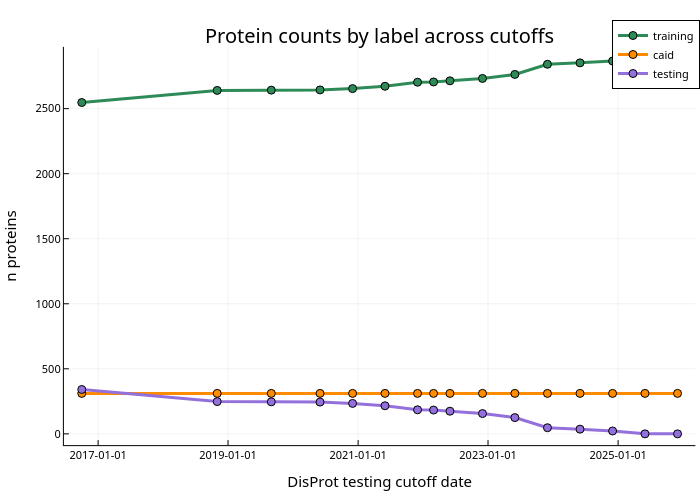

In [21]:
plot(
    sweep_proteins_wide.disprot_testing_cutoff_date,
    sweep_proteins_wide.training;
    label = "training",
    xlabel = "DisProt testing cutoff date",
    ylabel = "n proteins",
    title = "Protein counts by label across cutoffs",
    linewidth = 3,
    marker = :circle,
    color = :seagreen
)
plot!(
    sweep_proteins_wide.disprot_testing_cutoff_date,
    sweep_proteins_wide.caid;
    label = "caid",
    linewidth = 3,
    marker = :circle,
    color = :darkorange
)
plot!(
    sweep_proteins_wide.disprot_testing_cutoff_date,
    sweep_proteins_wide.testing;
    label = "testing",
    linewidth = 3,
    marker = :circle,
    color = :mediumpurple
)

### Plot 9: Cluster Counts vs Cutoff

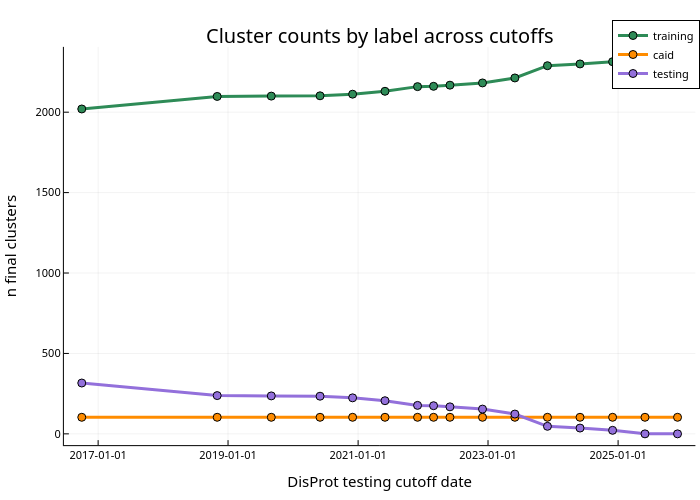

In [22]:
plot(
    sweep_clusters_wide.disprot_testing_cutoff_date,
    sweep_clusters_wide.training;
    label = "training",
    xlabel = "DisProt testing cutoff date",
    ylabel = "n final clusters",
    title = "Cluster counts by label across cutoffs",
    linewidth = 3,
    marker = :circle,
    color = :seagreen
)
plot!(
    sweep_clusters_wide.disprot_testing_cutoff_date,
    sweep_clusters_wide.caid;
    label = "caid",
    linewidth = 3,
    marker = :circle,
    color = :darkorange
)
plot!(
    sweep_clusters_wide.disprot_testing_cutoff_date,
    sweep_clusters_wide.testing;
    label = "testing",
    linewidth = 3,
    marker = :circle,
    color = :mediumpurple
)

### Plot 10: IDR-Binding Protein Counts vs Cutoff

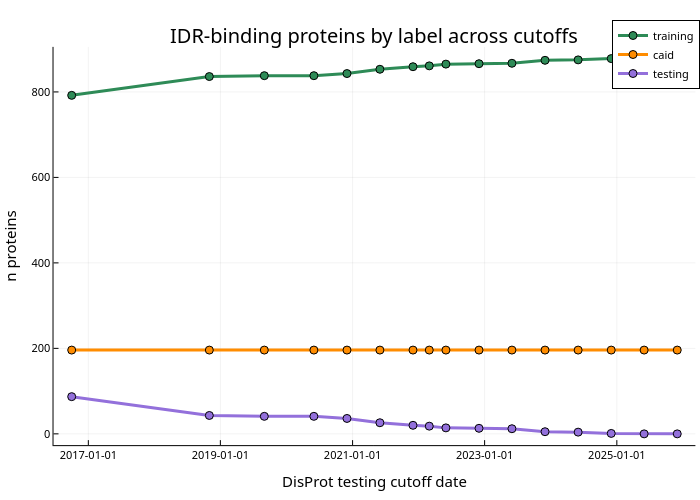

In [23]:
plot(
    sweep_binding_proteins_wide.disprot_testing_cutoff_date,
    sweep_binding_proteins_wide.training;
    label = "training",
    xlabel = "DisProt testing cutoff date",
    ylabel = "n proteins",
    title = "IDR-binding proteins by label across cutoffs",
    linewidth = 3,
    marker = :circle,
    color = :seagreen
)
plot!(
    sweep_binding_proteins_wide.disprot_testing_cutoff_date,
    sweep_binding_proteins_wide.caid;
    label = "caid",
    linewidth = 3,
    marker = :circle,
    color = :darkorange
)
plot!(
    sweep_binding_proteins_wide.disprot_testing_cutoff_date,
    sweep_binding_proteins_wide.testing;
    label = "testing",
    linewidth = 3,
    marker = :circle,
    color = :mediumpurple
)

### Plot 11: IDR-Binding Cluster Counts vs Cutoff

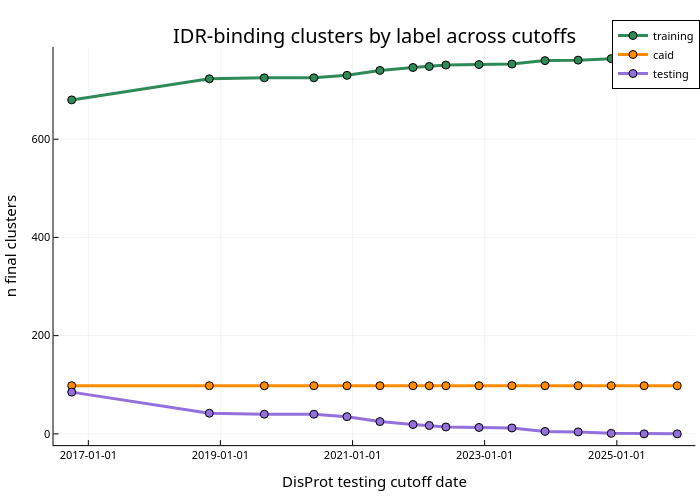

In [24]:
plot(
    sweep_binding_clusters_wide.disprot_testing_cutoff_date,
    sweep_binding_clusters_wide.training;
    label = "training",
    xlabel = "DisProt testing cutoff date",
    ylabel = "n final clusters",
    title = "IDR-binding clusters by label across cutoffs",
    linewidth = 3,
    marker = :circle,
    color = :seagreen
)
plot!(
    sweep_binding_clusters_wide.disprot_testing_cutoff_date,
    sweep_binding_clusters_wide.caid;
    label = "caid",
    linewidth = 3,
    marker = :circle,
    color = :darkorange
)
plot!(
    sweep_binding_clusters_wide.disprot_testing_cutoff_date,
    sweep_binding_clusters_wide.testing;
    label = "testing",
    linewidth = 3,
    marker = :circle,
    color = :mediumpurple
)

## Preliminary Cutoff Selection (No Fixed-Label Assignment Yet)

After reviewing the sweep, use cutoff `2020_12` (`Date(2020, 12, 1)`) for a preliminary sensitivity analysis.

This is still a preliminary step: missing fixed labels will remain unassigned for now.
Before any final reassignment, we still need to verify that the testing set contains
ELM motifs that are absent from the training set.

In [25]:
disprot_testing_cutoff_date = Date(2020, 12, 1)
# Preliminary analysis only: evaluate potential cutoff impact without committing label assignments.

dataset_stats_with_cutoff_labels = assign_missing_cluster_labels_by_disprot_cutoff(
    dataset_stats;
    disprot_testing_cutoff_date = disprot_testing_cutoff_date
)

first(
    select(
        dataset_stats_with_cutoff_labels,
        :protein_id,
        :final_cluster_id,
        :protein_oldest_disprot_release_date,
        :cluster_min_protein_oldest_disprot_release_date,
        :cluster_fixed_dataset_label,
        :cluster_disprot_cutoff_dataset_label
    ),
    10
)

Row,protein_id,final_cluster_id,protein_oldest_disprot_release_date,cluster_min_protein_oldest_disprot_release_date,cluster_fixed_dataset_label,cluster_disprot_cutoff_dataset_label
,String15,String15,Date?,Date?,String?,String?
1,A0A024B7W1,cluster_000001,2022-12-01,2016-10-01,training,training
2,A0A068MVV3,cluster_000002,2018-11-01,2016-10-01,missing,training
3,A0A078IB52,cluster_000003,2024-06-01,2024-06-01,caid,caid
4,A0A090N8E9,cluster_000004,2022-12-01,2018-11-01,training,training
5,A0A097F4I8,cluster_000005,2021-12-01,2016-10-01,training,training
6,A0A0B4JDC9,cluster_000006,2023-12-01,2016-10-01,caid,caid
7,A0A0C4DGY3,cluster_000007,2023-06-01,2023-06-01,missing,testing
8,A0A0G2JXC5,cluster_000008,2018-11-01,2018-11-01,training,training
9,A0A0G2KTI4,cluster_000009,2023-12-01,2016-10-01,training,training


In [26]:
disprot_cutoff_label_summary = summarize_dataset_labels_by_binding(
    dataset_stats_with_cutoff_labels;
    dataset_label_column = :cluster_disprot_cutoff_dataset_label
)

disprot_cutoff_label_summary

Row,dataset_label,n_proteins,n_final_clusters,n_idr_binding_proteins,n_idr_binding_clusters
,String,Int64,Int64,Int64,Int64
1,training,2654,2112,843,730
2,caid,311,103,196,98
3,testing,234,224,36,35


In [27]:
ordered_labels = ["training", "caid", "testing"]
summary_map = Dict(row.dataset_label => row for row in eachrow(disprot_cutoff_label_summary))

disprot_cutoff_label_summary_complete = DataFrame(
    dataset_label = ordered_labels,
    n_proteins = [haskey(summary_map, label) ? summary_map[label].n_proteins : 0 for label in ordered_labels],
    n_final_clusters = [haskey(summary_map, label) ? summary_map[label].n_final_clusters : 0 for label in ordered_labels],
    n_idr_binding_proteins = [haskey(summary_map, label) ? summary_map[label].n_idr_binding_proteins : 0 for label in ordered_labels],
    n_idr_binding_clusters = [haskey(summary_map, label) ? summary_map[label].n_idr_binding_clusters : 0 for label in ordered_labels]
)

disprot_cutoff_label_summary_complete

Row,dataset_label,n_proteins,n_final_clusters,n_idr_binding_proteins,n_idr_binding_clusters
,String,Int64,Int64,Int64,Int64
1,training,2654,2112,843,730
2,caid,311,103,196,98
3,testing,234,224,36,35


In [28]:
missing_fixed_clusters = unique(
    select(
        filter(row -> ismissing(row.cluster_fixed_dataset_label), dataset_stats_with_cutoff_labels),
        :final_cluster_id,
        :cluster_disprot_cutoff_dataset_label
    )
)

missing_fixed_cluster_distribution = combine(
    groupby(missing_fixed_clusters, :cluster_disprot_cutoff_dataset_label),
    nrow => :n_final_clusters
)
sort!(missing_fixed_cluster_distribution, :cluster_disprot_cutoff_dataset_label)

missing_fixed_cluster_distribution

Row,cluster_disprot_cutoff_dataset_label,n_final_clusters
,String?,Int64
1,testing,224
2,training,176


### Plot 3: Proteins by Final Label After Cutoff Reassignment

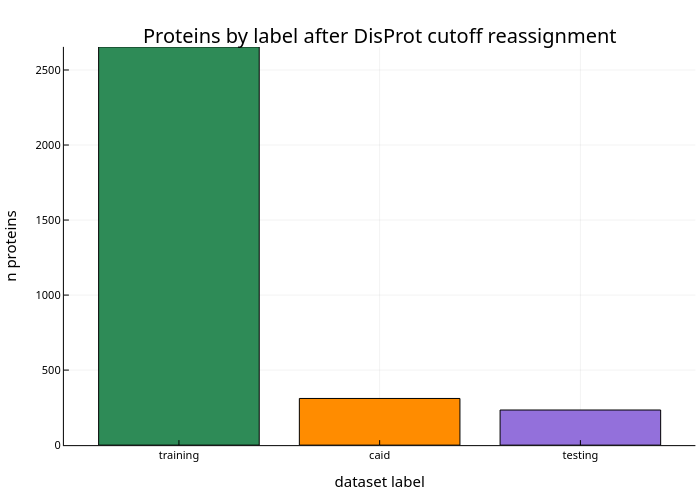

In [29]:
bar(
    disprot_cutoff_label_summary_complete.dataset_label,
    disprot_cutoff_label_summary_complete.n_proteins;
    xlabel = "dataset label",
    ylabel = "n proteins",
    title = "Proteins by label after DisProt cutoff reassignment",
    legend = false,
    color = [:seagreen, :darkorange, :mediumpurple]
)

### Plot 4: Clusters by Final Label After Cutoff Reassignment

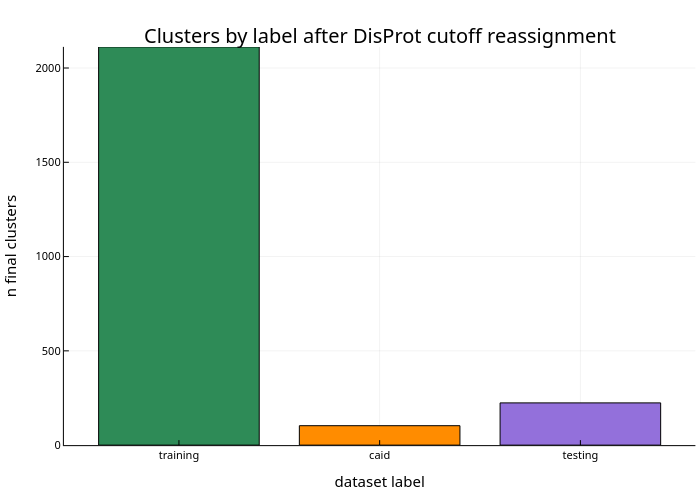

In [30]:
bar(
    disprot_cutoff_label_summary_complete.dataset_label,
    disprot_cutoff_label_summary_complete.n_final_clusters;
    xlabel = "dataset label",
    ylabel = "n final clusters",
    title = "Clusters by label after DisProt cutoff reassignment",
    legend = false,
    color = [:seagreen, :darkorange, :mediumpurple]
)

### Plot 5: IDR-Binding Proteins by Final Label

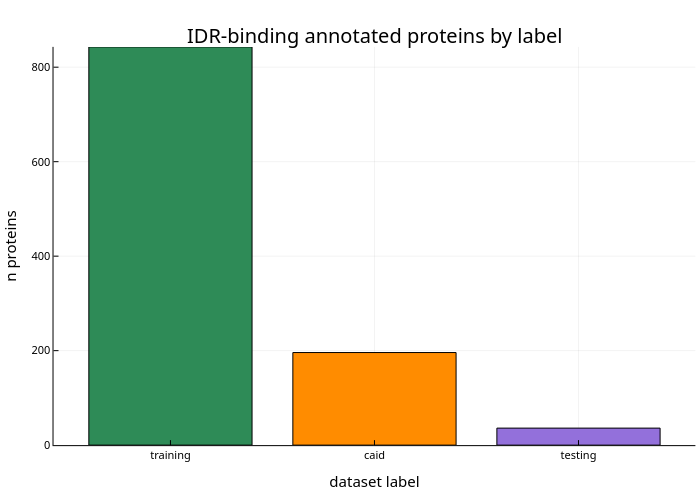

In [31]:
bar(
    disprot_cutoff_label_summary_complete.dataset_label,
    disprot_cutoff_label_summary_complete.n_idr_binding_proteins;
    xlabel = "dataset label",
    ylabel = "n proteins",
    title = "IDR-binding annotated proteins by label",
    legend = false,
    color = [:seagreen, :darkorange, :mediumpurple]
)

### Plot 6: IDR-Binding Clusters by Final Label

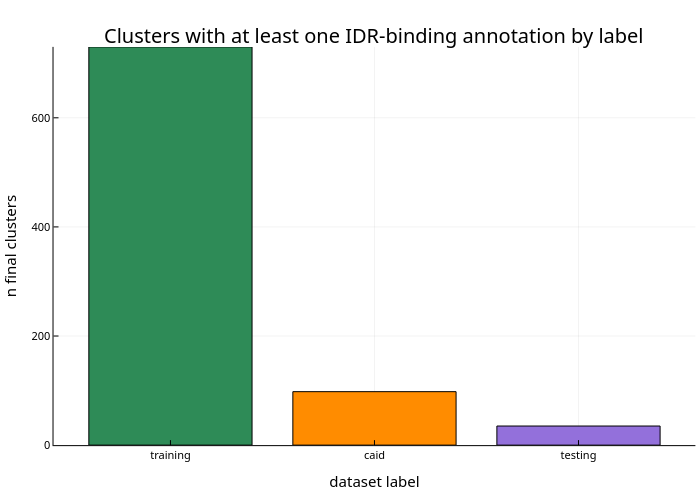

In [32]:
bar(
    disprot_cutoff_label_summary_complete.dataset_label,
    disprot_cutoff_label_summary_complete.n_idr_binding_clusters;
    xlabel = "dataset label",
    ylabel = "n final clusters",
    title = "Clusters with at least one IDR-binding annotation by label",
    legend = false,
    color = [:seagreen, :darkorange, :mediumpurple]
)

### Plot 7: Previously Missing Clusters Assigned by Cutoff

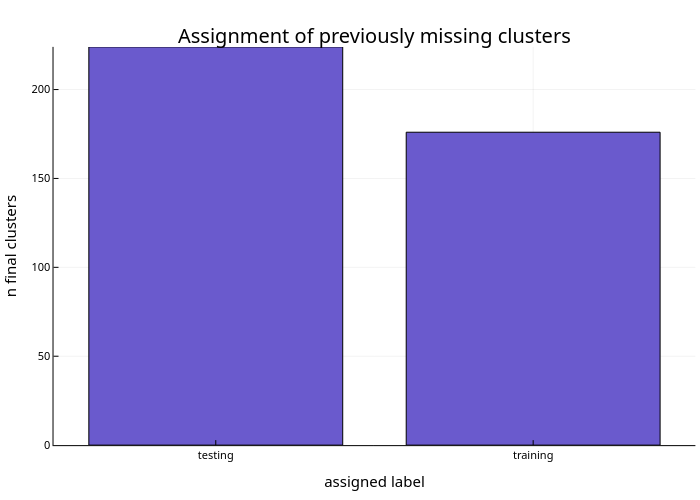

In [33]:
bar(
    string.(missing_fixed_cluster_distribution.cluster_disprot_cutoff_dataset_label),
    missing_fixed_cluster_distribution.n_final_clusters;
    xlabel = "assigned label",
    ylabel = "n final clusters",
    title = "Assignment of previously missing clusters",
    legend = false,
    color = :slateblue
)

### Final Check: Testing vs AF2 Training

In [34]:
testing_in_af2_training_count = count(
    row -> row.cluster_disprot_cutoff_dataset_label == "testing" && row.protein_in_af2_training_set,
    eachrow(dataset_stats_with_cutoff_labels)
)

testing_af2_overlap_summary = DataFrame(
    metric = ["testing_proteins_in_af2_training_set"],
    value = [testing_in_af2_training_count]
)

@assert testing_in_af2_training_count == 0 "Found proteins in testing set that belong to AF2 training set."

testing_af2_overlap_summary

Row,metric,value
,String,Int64
1,testing_proteins_in_af2_training_set,0
